# linear regression

In [13]:
import warnings
warnings.filterwarnings("ignore")

In [14]:
import pandas as pd 
import numpy as np



In [15]:
pd.read_csv(r"C:\Users\Admin\OneDrive\Desktop\ML\LungCapData.csv")

,LungCap,Age,Height,Smoke,Gender,Caesarean
0,6.475,6,62.1,no,male,no
1,10.125,18,74.7,yes,female,no
2,9.550,16,69.7,no,female,yes
3,11.125,14,71.0,no,male,no
4,4.800,5,56.9,no,male,no
...,...,...,...,...,...,...
720,5.725,9,56.0,no,female,no
721,9.050,18,72.0,yes,male,yes
722,3.850,11,60.5,yes,female,no
723,9.825,15,64.9,no,female,no


In [16]:
lung =pd.read_csv(r"C:\Users\Admin\OneDrive\Desktop\ML\LungCapData.csv")

In [17]:
lung

,LungCap,Age,Height,Smoke,Gender,Caesarean
0,6.475,6,62.1,no,male,no
1,10.125,18,74.7,yes,female,no
2,9.550,16,69.7,no,female,yes
3,11.125,14,71.0,no,male,no
4,4.800,5,56.9,no,male,no
...,...,...,...,...,...,...
720,5.725,9,56.0,no,female,no
721,9.050,18,72.0,yes,male,yes
722,3.850,11,60.5,yes,female,no
723,9.825,15,64.9,no,female,no


In [18]:
lung.isnull().sum()[lung.isnull().sum()>0]

Series([], dtype: int64)

In [19]:
lung.shape

(725, 6)

In [21]:
lung.Smoke.replace({"no":0,"yes":1},inplace=True)
lung.Gender.replace({"female":1,"male":0},inplace=True)
lung.Caesarean.replace({"yes":1,"no":0},inplace=True)

In [22]:
lung.head()

,LungCap,Age,Height,Smoke,Gender,Caesarean
0,6.475,6,62.1,0,0,0
1,10.125,18,74.7,1,1,0
2,9.550,16,69.7,0,1,1
3,11.125,14,71.0,0,0,0
4,4.800,5,56.9,0,0,0


In [24]:
from sklearn.model_selection import train_test_split
lung_train,lung_test=train_test_split(lung,test_size=.2)

In [25]:
lung_train_x=lung_train.iloc[::,1:]
lung_train_y=lung_train.iloc[::,0]


In [26]:
lung_test_x=lung_test.iloc[::,1:]
lung_test_y=lung_test.iloc[::,0]

In [27]:
lung_test_x

,Age,Height,Smoke,Gender,Caesarean
558,19,75.0,0,1,0
494,19,76.5,0,0,0
568,5,48.9,0,1,0
674,14,62.8,0,0,0
502,18,71.5,0,1,0
...,...,...,...,...,...
476,14,67.4,0,0,0
328,19,73.9,0,1,0
511,12,63.9,1,1,0
343,8,46.6,0,1,0


In [28]:
lung_test_y

558    10.575
494    14.675
568     1.325
674     7.475
502    10.600
        ...  
476     9.675
328     9.625
511     6.700
343     1.625
44      1.575
Name: LungCap, Length: 145, dtype: float64

In [29]:
from sklearn.linear_model import LinearRegression
linreg=LinearRegression()

In [30]:
linreg.fit(lung_test_x,lung_test_y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [33]:
linreg.score(lung_train_x,lung_train_y)

0.8547141535152005

In [34]:
lung_train_x.shape

(580, 5)

In [37]:
Rsquare=linreg.score(lung_train_x,lung_train_y)
n=lung_train_x.shape[0]
k=lung_train_x.shape[1]
adjrsquare=1-(1-Rsquare)*(n-1)/(n-k-1)
adjrsquare

0.8534485973611518

In [38]:
print(linreg.intercept_)

-10.801822853464909


In [39]:
linreg.coef_

array([ 0.1774279 ,  0.25871848, -0.41195087, -0.39449529, -0.14082357])

In [41]:
pred_train=linreg.predict(lung_train_x)
pred_test=linreg.predict(lung_test_x)

In [42]:
err_train=lung_train_y-pred_train
err_train

42     0.413377
107    0.532731
673   -1.192361
302    0.132051
687   -0.548083
         ...   
518    1.411224
291   -0.249682
227    1.145923
646   -1.618231
303   -0.074243
Name: LungCap, Length: 580, dtype: float64

In [43]:
err_train.mean()

np.float64(-0.032626424659730535)

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

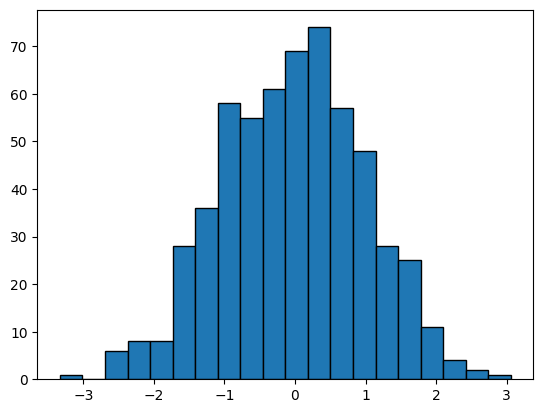

In [45]:
plt.hist(err_train,edgecolor="black",bins=20);

In [47]:
err_train.skew()

np.float64(-0.06357836792254319)

In [48]:
err_train.kurtosis()+3

np.float64(2.852887080021725)

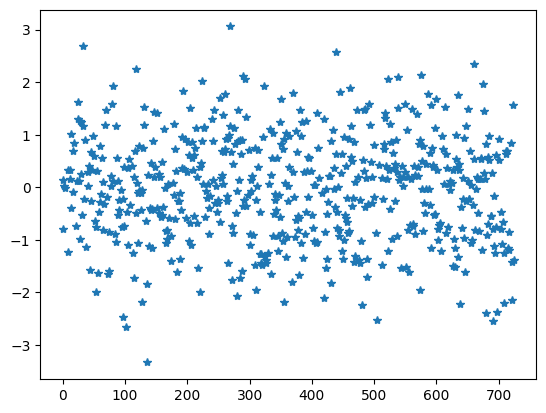

In [49]:
plt.plot(err_train,"*")

In [50]:
pred_act=pd.DataFrame()
pred_act['Actual']=lung_train_y
pred_act['Pred']=pred_train
pred_act

,Actual,Pred
42,5.875,5.461623
107,8.625,8.092269
673,5.950,7.142361
302,6.550,6.417949
687,7.475,8.023083
...,...,...
518,9.900,8.488776
291,10.450,10.699682
227,3.100,1.954077
646,7.850,9.468231


<Axes: xlabel='Actual', ylabel='Pred'>

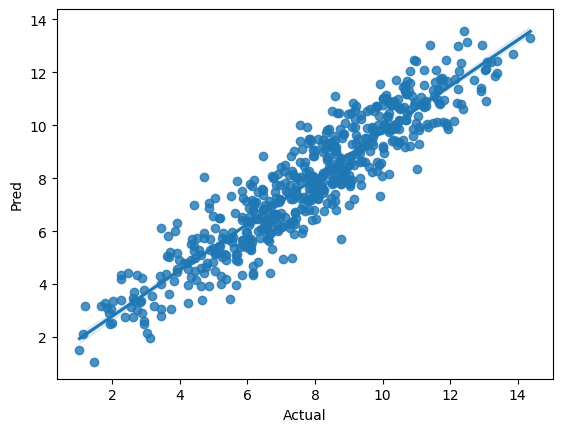

In [51]:
sns.regplot(x='Actual',y='Pred',data=pred_act)

In [52]:
err_test=lung_test_y-pred_test
err_test

558   -1.003698
494    2.313729
568   -1.017155
674   -0.454688
502    0.104245
         ...   
476    0.555207
328   -1.669107
511   -0.352976
343   -0.654386
44    -1.442565
Name: LungCap, Length: 145, dtype: float64

In [53]:
import numpy as np

In [54]:
mse=np.mean(np.square(err_test))
mse

np.float64(1.1760235293664096)

In [55]:
np.sqrt(mse)

np.float64(1.084446185555747)

In [56]:
mape=np.mean(np.abs(err_test*100/lung_test_y))

In [57]:
mape

np.float64(15.25816212381523)

In [58]:
acc=100-mape
print(acc)

84.74183787618477
